# 1. Data Perparation

In [ ]:
import tarfile
import shutil
from pathlib import Path
from collections import Counter
import wave
import soundfile as sf
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
import librosa
import matplotlib.pyplot as plt
import random
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix
import librosa.display

RANDOM_SEED = 10
np.random.seed(RANDOM_SEED)

## 1.1 Download and extract the Google Speech Commands Dataset

**Important:** every file is named

```
<word>/<speaker_id>_nohash_<utterance_index>.wav
```

e.g. `yes/0a7c2a8d_nohash_0.wav` — the 8-character hex string before `_nohash_` is a
**stable, anonymized speaker ID**.

In [2]:
DATA_ROOT = Path("data")
RAW_DIR = DATA_ROOT / "speech_commands_v0.02"
ARCHIVE_PATH = DATA_ROOT / "speech_commands_v0.02.tar.gz"
DATASET_URL = "http://download.tensorflow.org/data/speech_commands_v0.02.tar.gz"

DATA_ROOT.mkdir(parents=True, exist_ok=True)
RAW_DIR.mkdir(parents=True, exist_ok=True)

def download_dataset(url=DATASET_URL, archive_path=ARCHIVE_PATH, extract_dir=RAW_DIR):
    """Download the Speech Commands archive and extract it."""
    if not archive_path.exists():
        urllib.request.urlretrieve(url, archive_path)
        print("Download complete.")
    else:
        print("Archive already downloaded, skipping download.")

    if not (extract_dir / "yes").exists():
        with tarfile.open(archive_path, "r:gz") as tar:
            tar.extractall(path=extract_dir)
        print("Extraction complete.")
    else:
        print("Dataset already extracted, skipping extraction.")

download_dataset()

Archive already downloaded, skipping download.
Dataset already extracted, skipping extraction.


## 1.2. Selecting 10 target words

Chosen words:

`yes, no, up, down, left, right, on, off, stop, go`

In [3]:
SELECTED_WORDS = ["yes", "no", "up", "down", "left", "right", "on", "off", "stop", "go"]

available_words = {p.name for p in RAW_DIR.iterdir() if p.is_dir() and not p.name.startswith("_")}
missing = [w for w in SELECTED_WORDS if w not in available_words]
assert not missing, f"These words were not found in the dataset: {missing}"
print("All selected words found. Available word classes in dataset:", len(available_words))

All selected words found. Available word classes in dataset: 35


In [4]:
# Check signal freaquencies
rates = Counter()
for w in SELECTED_WORDS:
    for f in (RAW_DIR / w).glob("*.wav"):
        with wave.open(str(f), "rb") as wf:
            rates[wf.getframerate()] += 1

print(rates) # Counter({16000: 38546})

Counter({16000: 38546})


In [5]:
# Check signal durations
rows = []
for w in SELECTED_WORDS:
    for f in (RAW_DIR / w).glob("*.wav"):
        info = sf.info(f)
        rows.append({
            "word": w,
            "file": f.name,
            "samples": info.frames,
            "sr": info.samplerate,
            "duration": info.frames / info.samplerate,
        })

df = pd.DataFrame(rows)

print(df["duration"].describe()) # Different lengths (padding will be needed)

count    38546.000000
mean         0.982081
std          0.069204
min          0.298625
25%          1.000000
50%          1.000000
75%          1.000000
max          1.000000
Name: duration, dtype: float64


## 1.3 Parsing speaker IDs from filenames

Each filename looks like `0a7c2a8d_nohash_0.wav`. We split on `_nohash_` and take the first
part as the speaker ID.

In [6]:
def parse_speaker_id(filename: str) -> str:
    return filename.split("_nohash_")[0]

def build_file_index(raw_dir: Path, words):
    records = []
    for word in words:
        word_dir = raw_dir / word
        for wav_path in sorted(word_dir.glob("*.wav")):
            speaker_id = parse_speaker_id(wav_path.name)
            records.append({
                "filepath": str(wav_path),
                "word": word,
                "speaker_id": speaker_id,
            })
    return pd.DataFrame.from_records(records)

file_index = build_file_index(RAW_DIR, SELECTED_WORDS)
print(f"Total recordings found for the 10 selected words: {len(file_index)}")
print(f"Total unique speakers across these words: {file_index['speaker_id'].nunique()}")
file_index.groupby("word").size()

Total recordings found for the 10 selected words: 38546
Total unique speakers across these words: 2492


word
down     3917
go       3880
left     3801
no       3941
off      3745
on       3845
right    3778
stop     3872
up       3723
yes      4044
dtype: int64

## 1.4. Building a balanced subset

The raw counts per word are not perfectly equal (some words in Speech Commands have a few
thousand more recordings than others).

In [7]:
counts_per_word = file_index.groupby("word").size()
MAX_PER_WORD = min(counts_per_word.min(), 3700)  # cap at 3700
print("Recordings available per word:\n", counts_per_word)
print(f"\nUsing {MAX_PER_WORD} recordings per word for the balanced subset.")

def balanced_sample(df: pd.DataFrame, n_per_word: int, seed: int = RANDOM_SEED) -> pd.DataFrame:
    """For each word, sample n_per_word recordings, spreading the selection across as many
    different speakers as possible.
    """
    rng = np.random.RandomState(seed)
    selected_rows = []
    for word, group in df.groupby("word"):
        # shuffle speakers, then shuffle each speaker's recordings
        speakers = group["speaker_id"].unique()
        rng.shuffle(speakers)
        per_speaker_pool = {
            spk: group[group["speaker_id"] == spk].sample(frac=1.0, random_state=seed).to_dict("records")
            for spk in speakers
        }
        chosen = []
        # round-robin: take one recording from each speaker in turn until we hit n_per_word
        while len(chosen) < n_per_word and any(per_speaker_pool.values()):
            for spk in speakers:
                if per_speaker_pool[spk]:
                    chosen.append(per_speaker_pool[spk].pop())
                if len(chosen) >= n_per_word:
                    break
        selected_rows.extend(chosen)
    return pd.DataFrame(selected_rows).reset_index(drop=True)

balanced_df = balanced_sample(file_index, MAX_PER_WORD)
print("\nBalanced subset counts per word:")
print(balanced_df.groupby("word").size())
print(f"\nTotal recordings in balanced subset: {len(balanced_df)}")
print(f"Total unique speakers in balanced subset: {balanced_df['speaker_id'].nunique()}")


Recordings available per word:
 word
down     3917
go       3880
left     3801
no       3941
off      3745
on       3845
right    3778
stop     3872
up       3723
yes      4044
dtype: int64

Using 3700 recordings per word for the balanced subset.


C:\Users\avark\AppData\Local\Temp\ipykernel_31852\1398526463.py:15: UserWarning: you are shuffling a 'StringArray' object which is not a subclass of 'Sequence'; `shuffle` is not guaranteed to behave correctly. E.g., non-numpy array/tensor objects with view semantics may contain duplicates after shuffling.
  rng.shuffle(speakers)
C:\Users\avark\AppData\Local\Temp\ipykernel_31852\1398526463.py:15: UserWarning: you are shuffling a 'StringArray' object which is not a subclass of 'Sequence'; `shuffle` is not guaranteed to behave correctly. E.g., non-numpy array/tensor objects with view semantics may contain duplicates after shuffling.
  rng.shuffle(speakers)
C:\Users\avark\AppData\Local\Temp\ipykernel_31852\1398526463.py:15: UserWarning: you are shuffling a 'StringArray' object which is not a subclass of 'Sequence'; `shuffle` is not guaranteed to behave correctly. E.g., non-numpy array/tensor objects with view semantics may contain duplicates after shuffling.
  rng.shuffle(speakers)
C:\User


Balanced subset counts per word:
word
down     3700
go       3700
left     3700
no       3700
off      3700
on       3700
right    3700
stop     3700
up       3700
yes      3700
dtype: int64

Total recordings in balanced subset: 37000
Total unique speakers in balanced subset: 2492


## 1.5. Speaker-independent train/test split

This is the key requirement: **a speaker's recordings must all go to the same split** (train
*or* test, never both), and **every word must appear in both splits**.

Strategy:
1. Split the *set of speakers* into a train group (~80%) and a
   test group (~20%).
2. Assign every recording to train/test according to which group its speaker fell into.
3. Verify that (a) no speaker appears in both splits, and (b) every one of the 10 words has at
   least some recordings in both splits. If a word is missing from a split we automatically retry with a different random seed.

In [8]:
TEST_SPEAKER_FRACTION = 0.2

def speaker_independent_split(df: pd.DataFrame, words, test_frac=TEST_SPEAKER_FRACTION,
                               max_attempts=50):
    """Split recordings into train/test sets such that:
      - no speaker's recordings appear in both sets
      - every word in `words` is present in both sets
    Retries with different seeds if a particular split leaves a word missing from either set.
    """
    all_speakers = df["speaker_id"].unique()

    for attempt in range(max_attempts):
        seed = RANDOM_SEED + attempt
        train_speakers, test_speakers = train_test_split(
            all_speakers, test_size=test_frac, random_state=seed
        )
        train_speakers = set(train_speakers)
        test_speakers = set(test_speakers)

        train_df = df[df["speaker_id"].isin(train_speakers)].copy()
        test_df = df[df["speaker_id"].isin(test_speakers)].copy()

        words_in_train = set(train_df["word"].unique())
        words_in_test = set(test_df["word"].unique())

        if set(words) <= words_in_train and set(words) <= words_in_test:
            print(f"Found a valid speaker-independent split on attempt {attempt + 1} (seed={seed}).")
            return train_df.reset_index(drop=True), test_df.reset_index(drop=True)

    raise RuntimeError(
        "Could not find a split where all words appear in both sets after "
        f"{max_attempts} attempts. Try lowering test_frac or increasing MAX_PER_WORD."
    )

train_df, test_df = speaker_independent_split(balanced_df, SELECTED_WORDS)

print(f"\nTrain recordings: {len(train_df)}  |  Train speakers: {train_df['speaker_id'].nunique()}")
print(f"Test recordings:  {len(test_df)}  |  Test speakers:  {test_df['speaker_id'].nunique()}")


Found a valid speaker-independent split on attempt 1 (seed=10).

Train recordings: 29806  |  Train speakers: 1993
Test recordings:  7194  |  Test speakers:  499


## 1.6. Verify the split

In [9]:
# --- Check 1: no speaker overlap ---
train_speakers = set(train_df["speaker_id"].unique())
test_speakers = set(test_df["speaker_id"].unique())
overlap = train_speakers & test_speakers

assert len(overlap) == 0, f"Speaker leakage detected! Overlapping speakers: {overlap}"
print(f"No speaker overlap between train and test ({len(overlap)} overlapping speakers).")

# --- Check 2: all words present in both splits ---
missing_from_train = set(SELECTED_WORDS) - set(train_df["word"].unique())
missing_from_test = set(SELECTED_WORDS) - set(test_df["word"].unique())

assert not missing_from_train, f"Words missing from train set: {missing_from_train}"
assert not missing_from_test, f"Words missing from test set: {missing_from_test}"
print("All 10 selected words are present in both the train and test sets.")

# --- Per-word / per-split counts ---
summary = pd.DataFrame({
    "train_count": train_df.groupby("word").size(),
    "test_count": test_df.groupby("word").size(),
})
summary["total"] = summary["train_count"] + summary["test_count"]
summary["train_pct"] = (summary["train_count"] / summary["total"] * 100).round(1)
print("\nPer-word split summary:")
summary

No speaker overlap between train and test (0 overlapping speakers).
All 10 selected words are present in both the train and test sets.

Per-word split summary:


,train_count,test_count,total,train_pct
word,,,,
down,2983,717,3700,80.6
go,2994,706,3700,80.9
left,2982,718,3700,80.6
no,2967,733,3700,80.2
off,2938,762,3700,79.4
on,2968,732,3700,80.2
right,2977,723,3700,80.5
stop,2980,720,3700,80.5
up,3025,675,3700,81.8


## 1.7. Saving the manifest and materialize train/test folders

In [10]:
train_df["split"] = "train"
test_df["split"] = "test"
full_manifest = pd.concat([train_df, test_df], ignore_index=True)

manifest_path = DATA_ROOT / "dataset_manifest.csv"
full_manifest.to_csv(manifest_path, index=False)
print(f"Manifest saved to: {manifest_path.resolve()}")
full_manifest.head()

Manifest saved to: C:\Users\avark\OneDrive\Desktop\University\Master's degree\3 Semester\Natural Language and Speech Processing\NLP_task_2\data\dataset_manifest.csv


,filepath,word,speaker_id,split
0,data\speech_commands_v0.02\down\cc3d1613_nohas...,down,cc3d1613,train
1,data\speech_commands_v0.02\down\82b99576_nohas...,down,82b99576,train
2,data\speech_commands_v0.02\down\146d97db_nohas...,down,146d97db,train
3,data\speech_commands_v0.02\down\5a0bc987_nohas...,down,5a0bc987,train
4,data\speech_commands_v0.02\down\8910e5ef_nohas...,down,8910e5ef,train


In [11]:
def materialize_split(df: pd.DataFrame, split_name: str, dest_root: Path = DATA_ROOT):
    """Copy each recording into dest_root/<split_name>/<word>/<original_filename>.wav"""
    for row in df.itertuples(index=False):
        dest_dir = dest_root / split_name / row.word
        dest_dir.mkdir(parents=True, exist_ok=True)
        src = Path(row.filepath)
        dest = dest_dir / src.name
        if not dest.exists():
            shutil.copy2(src, dest)

materialize_split(train_df, "train")
materialize_split(test_df, "test")

for split in ["train", "test"]:
    for word in SELECTED_WORDS:
        n_files = len(list((DATA_ROOT / split / word).glob("*.wav")))
        print(f"  data/{split}/{word}: {n_files} files")

  data/train/yes: 2992 files
  data/train/no: 2967 files
  data/train/up: 3025 files
  data/train/down: 2983 files
  data/train/left: 2982 files
  data/train/right: 2977 files
  data/train/on: 2968 files
  data/train/off: 2938 files
  data/train/stop: 2980 files
  data/train/go: 2994 files
  data/test/yes: 708 files
  data/test/no: 733 files
  data/test/up: 675 files
  data/test/down: 717 files
  data/test/left: 718 files
  data/test/right: 723 files
  data/test/on: 732 files
  data/test/off: 762 files
  data/test/stop: 720 files
  data/test/go: 706 files


---
# 2: Feature Extraction

**Goal:** Convert every recording in `data/train/` and `data/test/` into a fixed-size feature
representation suitable as input to a speech-recognition model.

**Chosen representation: log-mel spectrogram.**

## 2.1 Why a log-mel spectrogram?

A **log-mel spectrogram** is a time–frequency representation obtained by:
1. Computing the short-time Fourier transform (STFT) of the waveform (splitting the signal
   into short overlapping frames and taking the magnitude/power spectrum of each),
2. Projecting the power spectrum onto a bank of triangular filters spaced on the **mel scale**
   (a perceptual pitch scale that is roughly linear at low frequencies and logarithmic at high
   frequencies, matching how the human ear resolves frequency),
3. Taking the logarithm of the mel-band energies (matching the roughly logarithmic way humans
   perceive loudness, and compressing the dynamic range).

**Why it is well suited for speech/keyword recognition:**
- It keeps the information that matters for distinguishing phonemes/words — the *shape* of the
  spectral envelope over time (formants, energy bursts, silence) — while discarding
  fine-grained phase information that is largely irrelevant for recognition.
- The mel scale allocates more resolution to the lower frequencies where most speech energy and
  phonetic contrasts live, and less to high frequencies, which matches human auditory
  perception and tends to improve robustness for speech tasks compared to a linear-frequency
  spectrogram.
- The log compression makes the representation less sensitive to overall loudness/gain
  differences between recordings and speakers.
- It produces a compact, fixed-structure 2-D "image" (mel-bands × time-frames) that is a
  standard, well-understood input for both classical ML (e.g. flattened + SVM/kNN) and deep
  learning models (CNNs, RNNs) — it is the de-facto standard front-end for keyword spotting and
  ASR systems (e.g. it underlies the standard TensorFlow Speech Commands baseline models and
  most CNN-based keyword spotters).

## 2.2 Preprocessing: consistent sampling rate & duration

- **The same sampling rate.** Speech Commands recordings are natively 16 kHz, but we
  double-check and resample any file that isn't, so all recordings are guaranteed to be at a
  common rate.
- **The same duration.** Most Speech Commands clips are exactly 1 second (16,000 samples) but a
  small fraction are shorter. We fix every clip to
  exactly **1.0 second**:
  - Clips **longer** than 1 s are **center-trimmed** to 1 s.
  - Clips **shorter** than 1 s are **zero-padded symmetrically** (equally on both sides) up to
    1 s.

In [12]:
TARGET_SR = 16000          # target sampling rate (Hz)
TARGET_DURATION_SEC = 1.0  # target signal duration (seconds)
TARGET_LEN = int(TARGET_SR * TARGET_DURATION_SEC)  # target length in samples (16000)

def load_and_fix_audio(filepath, target_sr=TARGET_SR, target_len=TARGET_LEN):
    """Load a wav file, resample to target_sr if necessary, and force it to exactly
    target_len samples.
    """
    y, sr = librosa.load(filepath, sr=None)  # load at native sample rate first

    if sr != target_sr:
        y = librosa.resample(y, orig_sr=sr, target_sr=target_sr)
        sr = target_sr

    if len(y) > target_len:
        # center-trim
        start = (len(y) - target_len) // 2
        y = y[start:start + target_len]
    elif len(y) < target_len:
        # symmetric zero-padding
        pad_total = target_len - len(y)
        pad_left = pad_total // 2
        pad_right = pad_total - pad_left
        y = np.pad(y, (pad_left, pad_right), mode="constant")

    return y.astype(np.float32), sr

## 2.3 Feature extraction parameters

Used parameters:
| Parameter                     | Value                | Notes |
|--------------------------------|---------------------|-------|
| Sampling rate                 | 16,000 Hz            | native rate of the dataset |
| Signal duration                | 1.0 s (16,000 samples) | fixed via trim/zero-pad |
| Frame / window length          | 25 ms (400 samples)  | standard analysis window for speech |
| Frame shift (hop length)       | 10 ms (160 samples)  | 60% overlap between consecutive frames |
| Window function                 | Hamming               | tapers frame edges, reduces spectral leakage |
| FFT size (`n_fft`)             | 512                   | ≥ window length, zero-padded internally by librosa |
| Number of mel filters (`n_mels`) | 40                  | typical for keyword spotting (26–80 common range) |
| Frequency range                | 20 Hz – 8000 Hz (Nyquist) | covers full speech-relevant band at 16 kHz |
| Amplitude scaling               | log (dB), `ref=np.max` | log-compression, normalized per-utterance to its own peak |

In [13]:
FEATURE_PARAMS = {
    "sample_rate": TARGET_SR,
    "n_fft": 512,          # FFT size
    "win_length": 400,     # 25 ms window @ 16 kHz
    "hop_length": 160,     # 10 ms frame shift @ 16 kHz
    "window": "hamming",   # window function
    "n_mels": 40,          # number of mel filters
    "fmin": 20,            # Hz
    "fmax": TARGET_SR // 2,  # Nyquist frequency, 8000 Hz
}


def extract_log_mel_spectrogram(y, sr=TARGET_SR, params=FEATURE_PARAMS):
    """Compute a log-mel spectrogram for a fixed-length waveform `y`.
    Returns a 2-D array of shape (n_mels, n_frames).
    """
    mel_spec = librosa.feature.melspectrogram(
        y=y,
        sr=sr,
        n_fft=params["n_fft"],
        win_length=params["win_length"],
        hop_length=params["hop_length"],
        window=params["window"],
        n_mels=params["n_mels"],
        fmin=params["fmin"],
        fmax=params["fmax"],
        power=2.0,
    )
    log_mel_spec = librosa.power_to_db(mel_spec, ref=np.max)
    return log_mel_spec.astype(np.float32)


## 2.4 Extract features for the entire dataset

We now apply `load_and_fix_audio` + `extract_log_mel_spectrogram` to every recording listed in
`dataset_manifest.csv` (both train and test), stacking the results into single arrays:

- `X_train`, `X_test`: shape `(num_examples, n_mels, n_frames)`
- `y_train`, `y_test`: word labels (strings)
- `speakers_train`, `speakers_test`: speaker IDs (kept for reference / any future
  speaker-related analysis)

These are saved to disk as compressed `.npz` files so later notebook sections (model training)
can simply load them without re-running feature extraction.

In [14]:
def build_feature_matrix(df: pd.DataFrame):
    features, labels, speakers, paths = [], [], [], []
    for row in df.itertuples(index=False):
        y_wave, sr_ = load_and_fix_audio(row.filepath)
        feat = extract_log_mel_spectrogram(y_wave, sr_)
        features.append(feat)
        labels.append(row.word)
        speakers.append(row.speaker_id)
        paths.append(row.filepath)
    X = np.stack(features, axis=0)
    y = np.array(labels)
    speakers = np.array(speakers)
    return X, y, speakers, paths

print("Extracting features for the TRAIN set...")
X_train, y_train, speakers_train, paths_train = build_feature_matrix(train_df)
print("Extracting features for the TEST set...")
X_test, y_test, speakers_test, paths_test = build_feature_matrix(test_df)

print(f"\nX_train shape: {X_train.shape}   (num_examples, n_mels, n_frames)")
print(f"X_test shape:  {X_test.shape}")

FEATURES_PATH = DATA_ROOT / "features_logmel.npz"
np.savez_compressed(
    FEATURES_PATH,
    X_train=X_train, y_train=y_train, speakers_train=speakers_train,
    X_test=X_test, y_test=y_test, speakers_test=speakers_test,
)

Extracting features for the TRAIN set...
Extracting features for the TEST set...

X_train shape: (29806, 40, 101)   (num_examples, n_mels, n_frames)
X_test shape:  (7194, 40, 101)


## 2.5 Feature plot and interpretation

Below we plot the waveform and the corresponding log-mel spectrogram for one example
recording of the word **"yes"**.

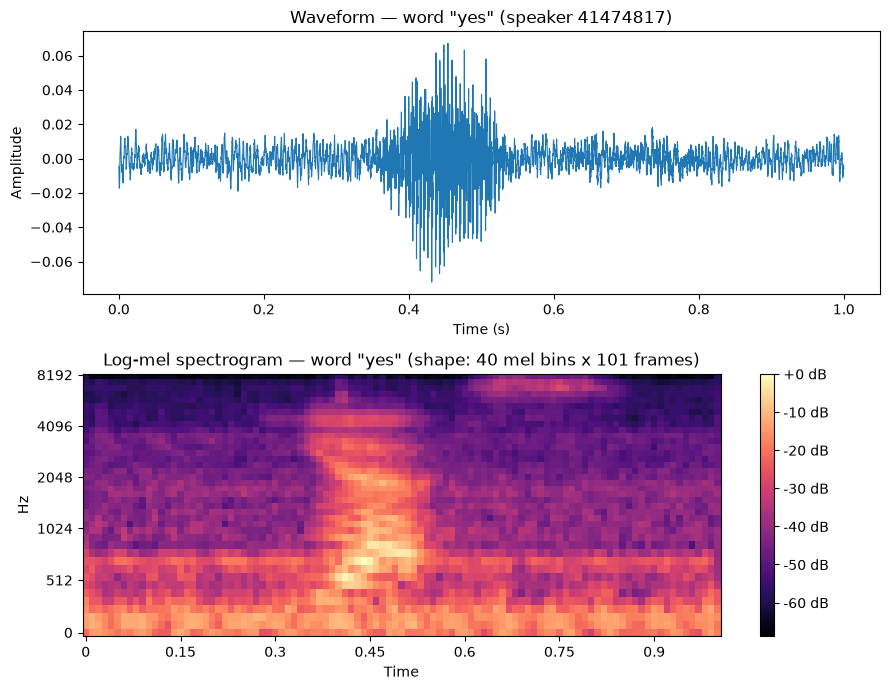

In [15]:
EXAMPLE_WORD = "yes"

example_row = train_df[train_df["word"] == EXAMPLE_WORD].iloc[0]
example_y, example_sr = load_and_fix_audio(example_row.filepath)
example_feat = extract_log_mel_spectrogram(example_y, example_sr)

fig, axes = plt.subplots(2, 1, figsize=(9, 7))

# --- Waveform ---
t = np.linspace(0, TARGET_DURATION_SEC, len(example_y))
axes[0].plot(t, example_y, linewidth=0.8)
axes[0].set_title(f'Waveform — word "{EXAMPLE_WORD}" (speaker {example_row.speaker_id})')
axes[0].set_xlabel("Time (s)")
axes[0].set_ylabel("Amplitude")

# --- Log-mel spectrogram ---
img = librosa.display.specshow(
    example_feat,
    sr=example_sr,
    hop_length=FEATURE_PARAMS["hop_length"],
    x_axis="time",
    y_axis="mel",
    fmax=FEATURE_PARAMS["fmax"],
    ax=axes[1],
)
axes[1].set_title(f'Log-mel spectrogram — word "{EXAMPLE_WORD}" '
                   f'(shape: {example_feat.shape[0]} mel bins x {example_feat.shape[1]} frames)')
fig.colorbar(img, ax=axes[1], format="%+2.0f dB")

plt.tight_layout()
plt.show()

**Interpretation:**

- The **waveform** (top) shows the raw amplitude over the fixed 1-second window. The spoken
  word occupies only part of the 1-second frame; the flat regions at the start/end are the
  zero-padding (or near-silence) around the utterance.
- In the **log-mel spectrogram** (bottom), the x-axis is time (frames, using the 10 ms hop) and
  the y-axis is mel frequency (40 mel bands, up to 8 kHz). Color encodes log-energy in dB
  (yellow/bright = high energy, dark blue/purple = low energy).
- During the silent/padded regions, energy is low and roughly uniform across frequency (dark
  bands at the start and/or end).
- During the spoken word itself, we see a burst of increased energy in the low-to-mid mel bands
  that evolves over time — the changing pattern corresponds to the transition between phonemes
  (e.g. for "yes": the /j/ glide, the vowel /ɛ/ with visible formant structure as horizontal
  energy bands, then the fricative /s/ typically showing energy shifted toward higher
  frequencies at the end).
- This confirms the log-mel spectrogram captures exactly the kind of time-varying spectral
  structure that distinguishes one spoken word from another, which is why it's an effective
  input representation for a speech/keyword recognition model.

---
# 3. Model Selection

## 3.1 Model overview

A single fixed convolutional neural network (CNN) is used in all experiments. Its purpose is to serve as a consistent baseline for measuring the effect of different noise conditions, not to maximize accuracy. The model takes a log-mel spectrogram of size 40 × 101 as a one-channel image and outputs a probability for each of the 10 target words. A CNN suits this input because a spectrogram is image-like: convolutional filters learn local time-frequency patterns (formant bands, fricative noise, stop bursts) and detect them regardless of where they occur in time, using relatively few parameters.

## 3.2 Architecture

| # | Layer | Configuration | Output shape | Parameters |
|---|-------|---------------|--------------|-----------:|
| 0 | Input | log-mel spectrogram, 1 channel | 40 × 101 × 1 | 0 |
| 1 | Conv2D + ReLU | 16 filters, 3×3, stride 1, "same" padding | 40 × 101 × 16 | 160 |
| 2 | MaxPooling2D | 2×2 | 20 × 50 × 16 | 0 |
| 3 | Conv2D + ReLU | 32 filters, 3×3, stride 1, "same" padding | 20 × 50 × 32 | 4,640 |
| 4 | MaxPooling2D | 2×2 | 10 × 25 × 32 | 0 |
| 5 | Conv2D + ReLU | 64 filters, 3×3, stride 1, "same" padding | 10 × 25 × 64 | 18,496 |
| 6 | MaxPooling2D | 2×2 | 5 × 12 × 64 | 0 |
| 7 | Global Average Pooling | averages each feature map | 64 | 0 |
| 8 | Dropout | rate 0.3 | 64 | 0 |
| 9 | Dense + ReLU | 64 units | 64 | 4,160 |
| 10 | Dense (output) + Softmax | 10 units (one per word) | 10 | 650 |

**Total trainable parameters: 28,106.**

Design choices:
- **Three convolutional blocks (16 → 32 → 64 filters):** the number of filters doubles as the spatial resolution halves, a standard pattern. Early layers capture simple local patterns, and deeper layers combine them into word-level structure.
- **ReLU activation:** adds non-linearity, is cheap to compute, and trains reliably.
- **Max pooling:** reduces the time-frequency resolution and gives tolerance to small shifts in time and frequency.
- **Global average pooling instead of flattening:** keeps the parameter count small and reduces overfitting.
- **Dropout (0.3):** regularizes the dense part of the network.
- **Softmax output with 10 units:** converts the outputs into a probability distribution over the 10 words (yes, no, up, down, left, right, on, off, stop, go).

## 3.3 Training parameters

| Parameter | Value |
|-----------|-------|
| Loss function | Sparse categorical cross-entropy (integer labels) |
| Optimizer | Adam |
| Learning rate | 0.001 (constant) |
| Batch size | 64 |
| Number of epochs | 20 (fixed, no early stopping) |
| Final model | Weights after the last epoch |
| Metric | Accuracy |
| Input normalization | Per-feature mean and standard deviation, computed on the training set only and applied to both training and test sets |

---
# 4. Modelling

## 4.1 Model training

Loaded saved features.
X_train: (29806, 40, 101, 1)  X_test: (7194, 40, 101, 1)
y_train: (29806,)  y_test: (7194,)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 40, 101, 16)    │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 20, 50, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 20, 50, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 10, 25, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 10, 25, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 5, 12, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 28,106 (109.79 KB)

 Trainable params: 28,106 (109.79 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
466/466 - 6s - 12ms/step - accuracy: 0.2447 - loss: 2.0472
Epoch 2/20
466/466 - 5s - 10ms/step - accuracy: 0.5237 - loss: 1.3968
Epoch 3/20
466/466 - 5s - 10ms/step - accuracy: 0.6923 - loss: 0.9337
Epoch 4/20
466/466 - 5s - 10ms/step - accuracy: 0.7653 - loss: 0.7120
Epoch 5/20
466/466 - 5s - 11ms/step - accuracy: 0.8043 - loss: 0.5977
Epoch 6/20
466/466 - 5s - 11ms/step - accuracy: 0.8276 - loss: 0.5312
Epoch 7/20
466/466 - 5s - 11ms/step - accuracy: 0.8405 - loss: 0.4847
Epoch 8/20
466/466 - 5s - 11ms/step - accuracy: 0.8541 - loss: 0.4456
Epoch 9/20
466/466 - 5s - 11ms/step - accuracy: 0.8594 - loss: 0.4232
Epoch 10/20
466/466 - 5s - 11ms/step - accuracy: 0.8685 - loss: 0.3978
Epoch 11/20
466/466 - 5s - 11ms/step - accuracy: 0.8713 - loss: 0.3797
Epoch 12/20
466/466 - 5s - 11ms/step - accuracy: 0.8789 - loss: 0.3634
Epoch 13/20
466/466 - 5s - 11ms/step - accuracy: 0.8817 - loss: 0.3503
Epoch 14/20
466/466 - 5s - 11ms/step - accuracy: 0.8867 - loss: 0.3401
Epoch 15/20
466

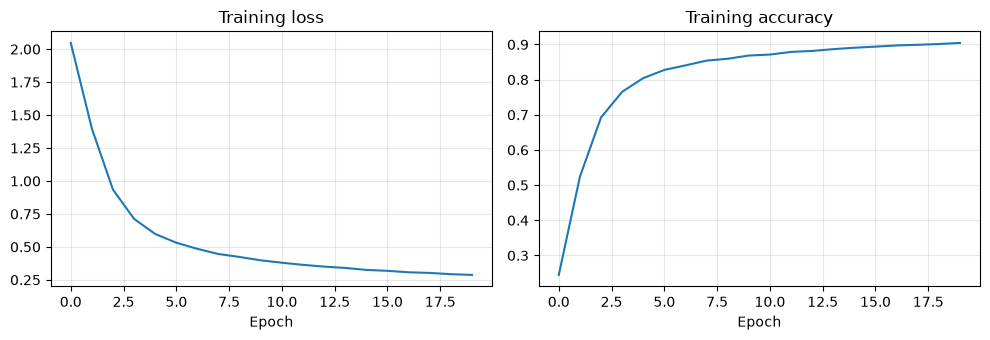


Test loss: 0.2445 | Test accuracy: 0.9137

Per-class report:
              precision    recall  f1-score   support

         yes      0.979     0.936     0.957       708
          no      0.947     0.870     0.907       733
          up      0.891     0.911     0.901       675
        down      0.828     0.925     0.874       717
        left      0.919     0.912     0.915       718
       right      0.982     0.923     0.951       723
          on      0.920     0.929     0.925       732
         off      0.885     0.915     0.899       762
        stop      0.939     0.942     0.940       720
          go      0.868     0.874     0.871       706

    accuracy                          0.914      7194
   macro avg      0.916     0.914     0.914      7194
weighted avg      0.916     0.914     0.914      7194



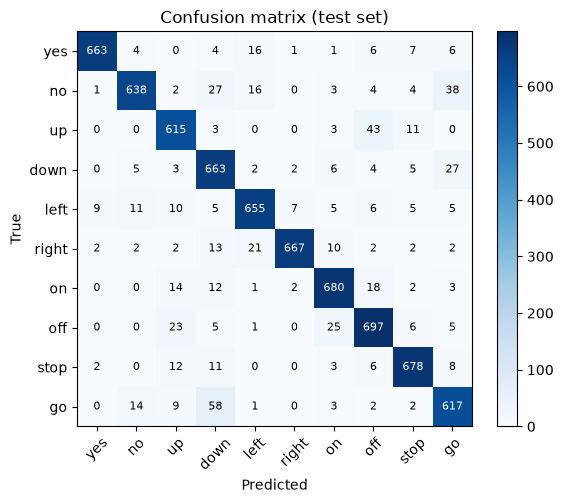

In [16]:
SEED = 10

# Training parameters
BATCH_SIZE = 64
EPOCHS = 20
LEARNING_RATE = 1e-3

# ---------------- REPRODUCIBILITY ----------------
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# ---------------- LOAD SAVED FEATURES ----------------
data = np.load(DATA_ROOT / "features_logmel.npz")

# Add the channel dimension required by Conv2D
X_train = data["X_train"][..., np.newaxis]
X_test = data["X_test"][..., np.newaxis]

# Convert string labels into integer labels
word_to_idx = {word: i for i, word in enumerate(SELECTED_WORDS)}
idx_to_word = {i: word for word, i in word_to_idx.items()}

y_train = np.array([word_to_idx[word] for word in data["y_train"]])
y_test = np.array([word_to_idx[word] for word in data["y_test"]])

print("Loaded saved features.")
print("X_train:", X_train.shape, " X_test:", X_test.shape)
print("y_train:", y_train.shape, " y_test:", y_test.shape)

# ---------------- NORMALIZATION ----------------
mean = X_train.mean(axis=(0, 2), keepdims=True)
std = X_train.std(axis=(0, 2), keepdims=True) + 1e-8
X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

# ---------------- MODEL ----------------
def build_model(input_shape, n_classes):
    return models.Sequential([
        layers.Input(shape=input_shape),

        layers.Conv2D(16, (3, 3), padding="same", activation="relu"),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
        layers.MaxPooling2D((2, 2)),

        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.3),
        layers.Dense(64, activation="relu"),
        layers.Dense(n_classes, activation="softmax"),
    ])


model = build_model(X_train.shape[1:], len(SELECTED_WORDS))
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
model.summary()

# ---------------- TRAINING ----------------
history = model.fit(
    X_train, y_train,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    shuffle=True,
    verbose=2,
)

# Training curves
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(history.history["loss"]);     ax[0].set_title("Training loss")
ax[1].plot(history.history["accuracy"]); ax[1].set_title("Training accuracy")
for a in ax:
    a.set_xlabel("Epoch"); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# ---------------- TESTING ----------------
test_loss, test_acc = model.evaluate(X_test, y_test, batch_size=BATCH_SIZE, verbose=0)
print(f"\nTest loss: {test_loss:.4f} | Test accuracy: {test_acc:.4f}")

y_pred = np.argmax(model.predict(X_test, batch_size=BATCH_SIZE, verbose=0), axis=1)

print("\nPer-class report:")
print(classification_report(y_test, y_pred, target_names=SELECTED_WORDS, digits=3))

cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(SELECTED_WORDS))); ax.set_xticklabels(SELECTED_WORDS, rotation=45)
ax.set_yticks(range(len(SELECTED_WORDS))); ax.set_yticklabels(SELECTED_WORDS)
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title("Confusion matrix (test set)")
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=8)
plt.colorbar(im); plt.tight_layout(); plt.show()


## 4.2 Synthetic noise

In [17]:
SNR_LEVELS_DB = [30, 20, 10, 0]
NOISE_SEED = 123


def add_white_noise(y, snr_db, rng):
    """Add Gaussian noise to y at the requested signal-to-noise ratio."""
    signal_rms = np.sqrt(np.mean(y ** 2))
    if signal_rms == 0:
        return y.copy()

    noise = rng.normal(size=y.shape).astype(np.float32)
    noise_rms = np.sqrt(np.mean(noise ** 2))
    target_noise_rms = signal_rms / (10 ** (snr_db / 20))
    noise = noise * (target_noise_rms / (noise_rms + 1e-8))
    return (y + noise).astype(np.float32)


def build_noisy_test_features(snr_db, seed):
    """Load test audio, add white noise, and extract the same log-mel features."""
    rng = np.random.default_rng(seed)
    features = []

    for filepath in test_df["filepath"]:
        waveform, sample_rate = load_and_fix_audio(filepath)
        noisy_waveform = add_white_noise(waveform, snr_db, rng)
        feature = extract_log_mel_spectrogram(noisy_waveform, sample_rate)
        features.append(feature)

    return np.stack(features, axis=0)[..., np.newaxis]


noise_results = []
for snr_db in SNR_LEVELS_DB:
    print(f"Evaluating test set with white noise at {snr_db} dB SNR...")

    X_test_noisy = build_noisy_test_features(snr_db, NOISE_SEED + snr_db)
    X_test_noisy = (X_test_noisy - mean) / std

    noisy_loss, noisy_accuracy = model.evaluate(
        X_test_noisy, y_test, batch_size=BATCH_SIZE, verbose=0
    )
    noise_results.append({
        "SNR_dB": snr_db,
        "test_loss": noisy_loss,
        "test_accuracy": noisy_accuracy,
    })

noise_results = pd.DataFrame(noise_results).sort_values("SNR_dB", ascending=False)
print("\nPerformance under synthetic white Gaussian noise:")
display(noise_results)

Evaluating test set with white noise at 30 dB SNR...
Evaluating test set with white noise at 20 dB SNR...
Evaluating test set with white noise at 10 dB SNR...
Evaluating test set with white noise at 0 dB SNR...

Performance under synthetic white Gaussian noise:


,SNR_dB,test_loss,test_accuracy
0,30,0.283957,0.905199
1,20,0.452948,0.835835
2,10,0.825665,0.702113
3,0,1.672999,0.350848


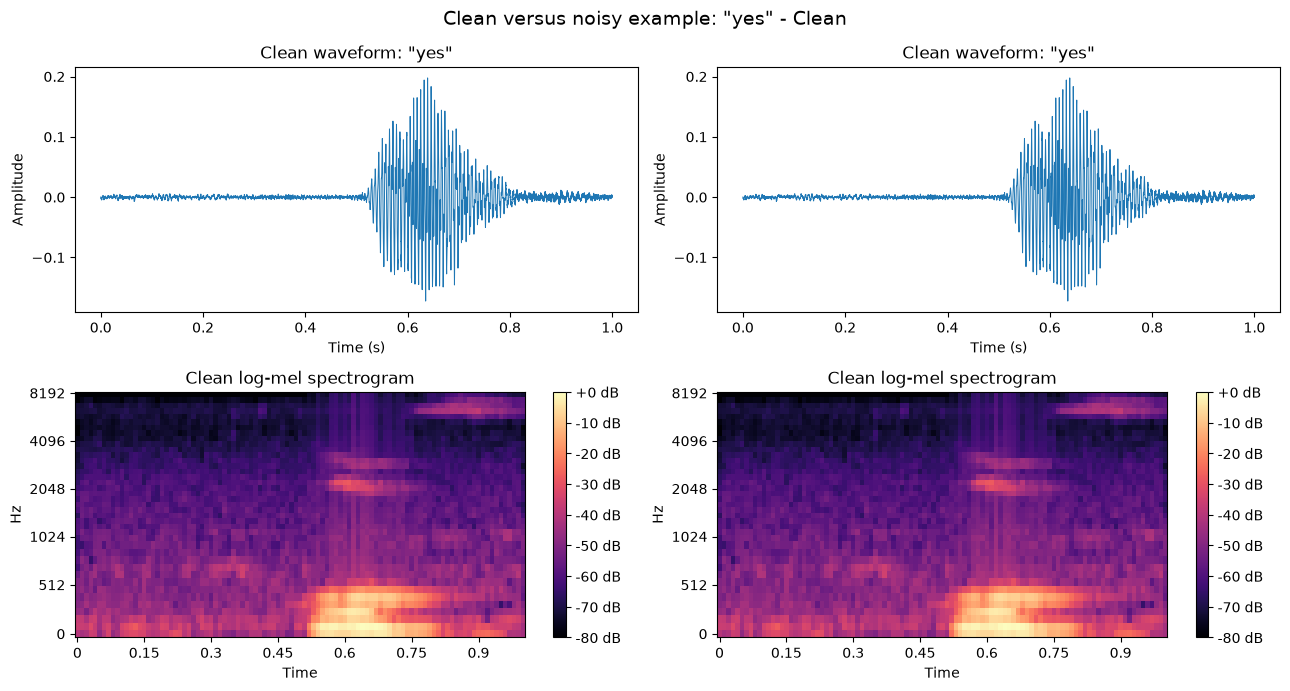

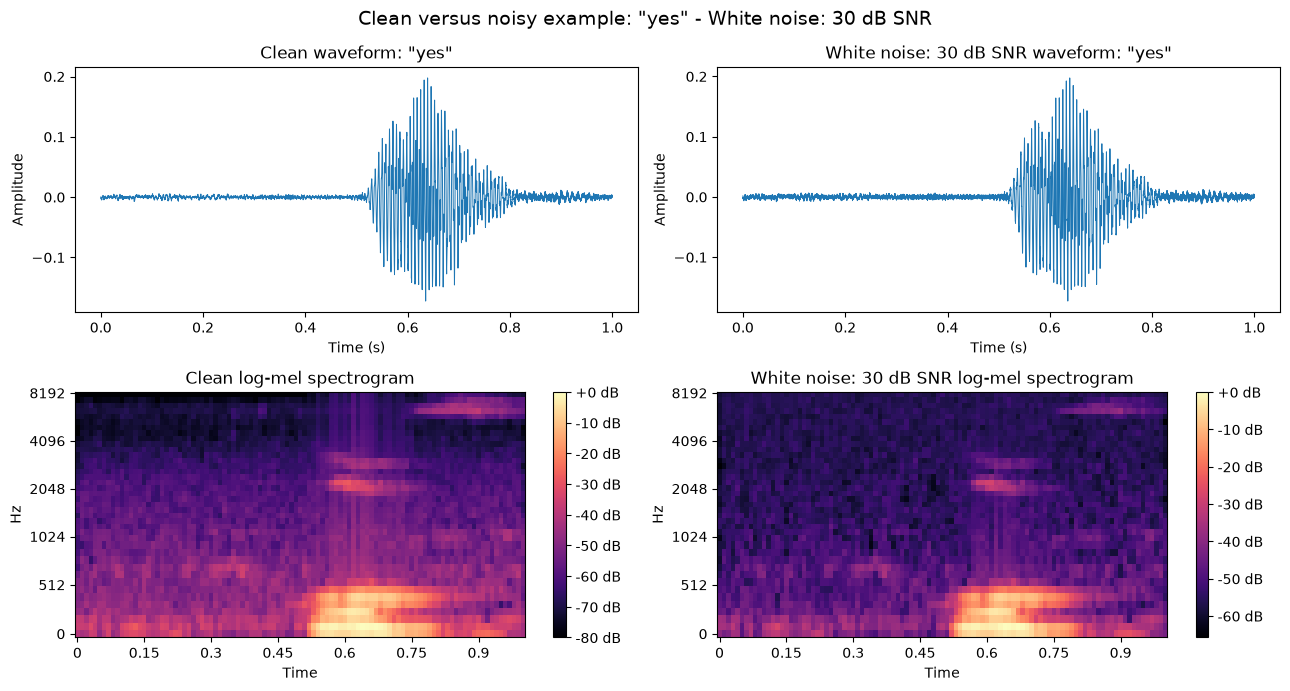

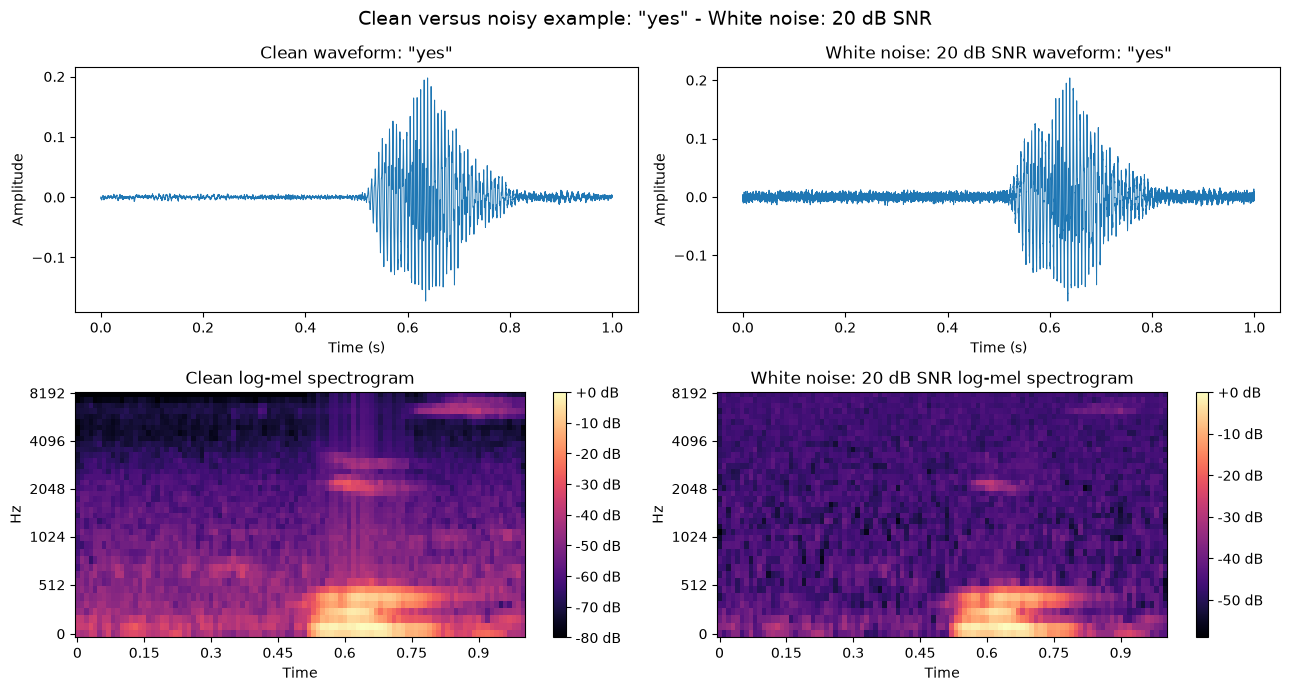

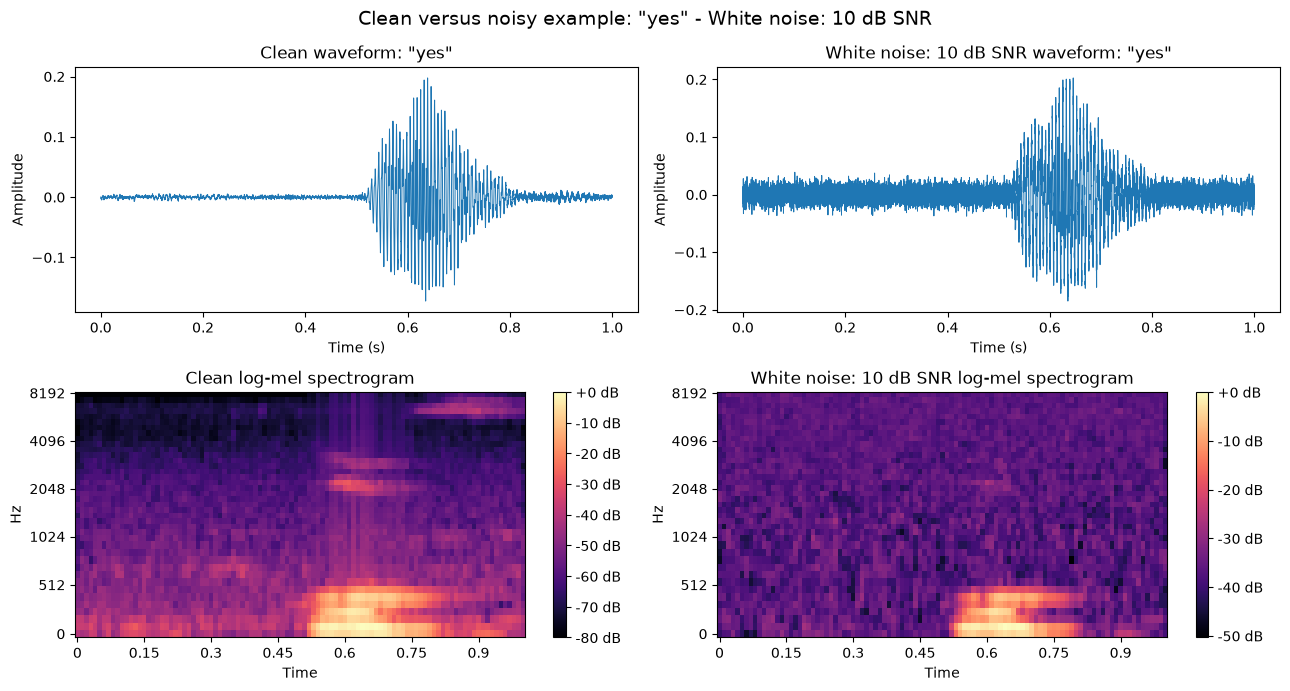

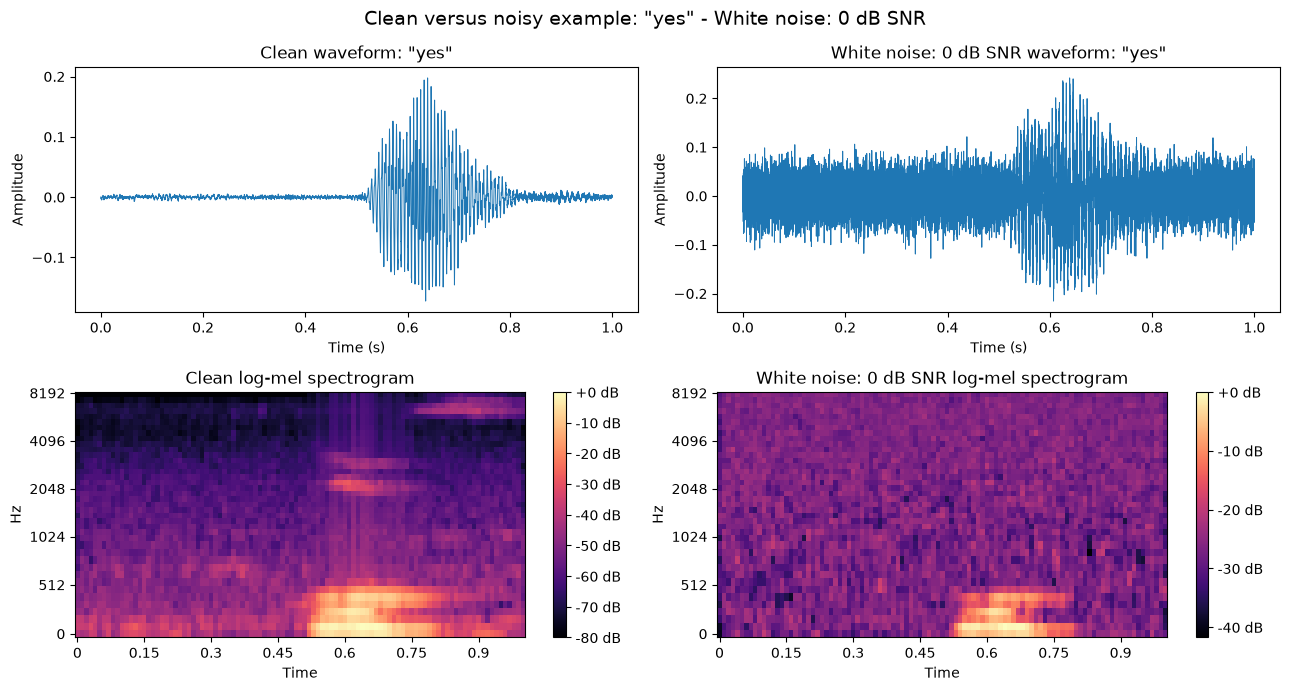

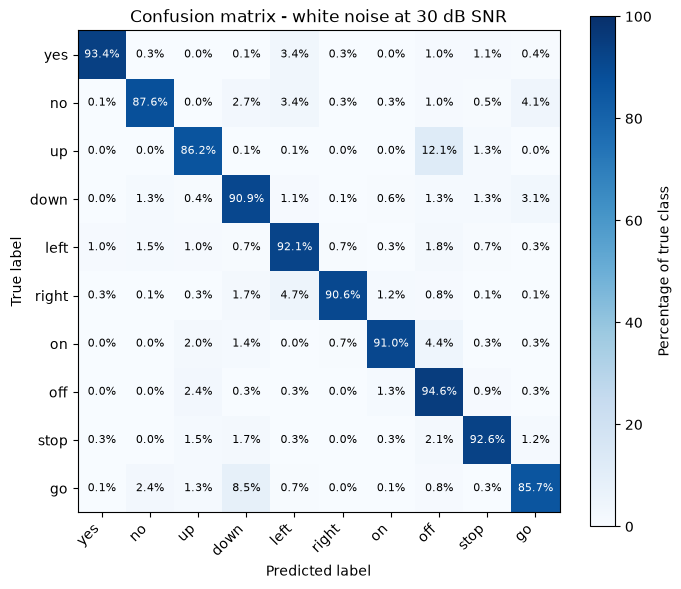

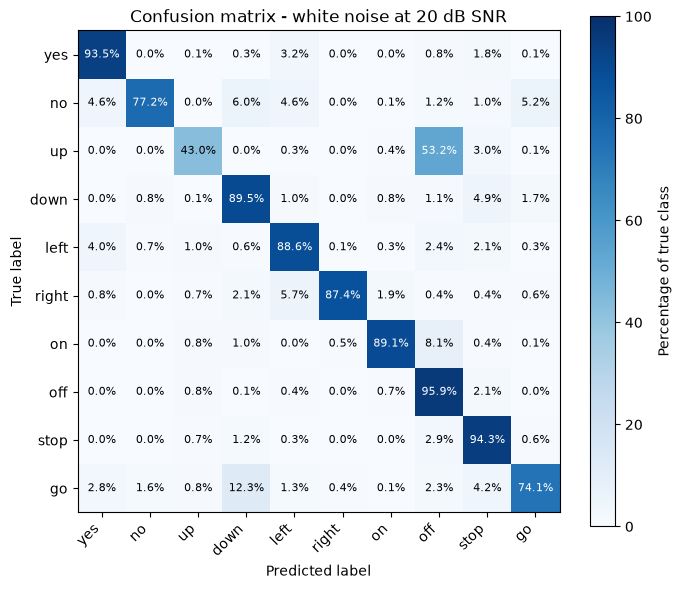

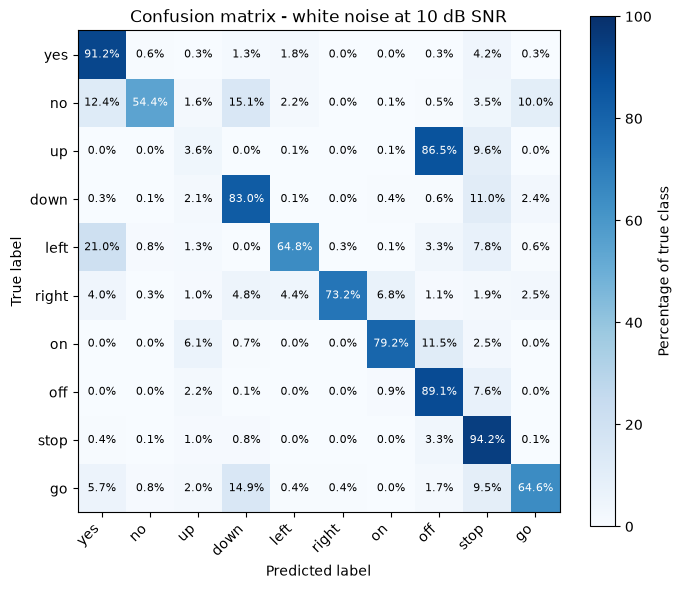

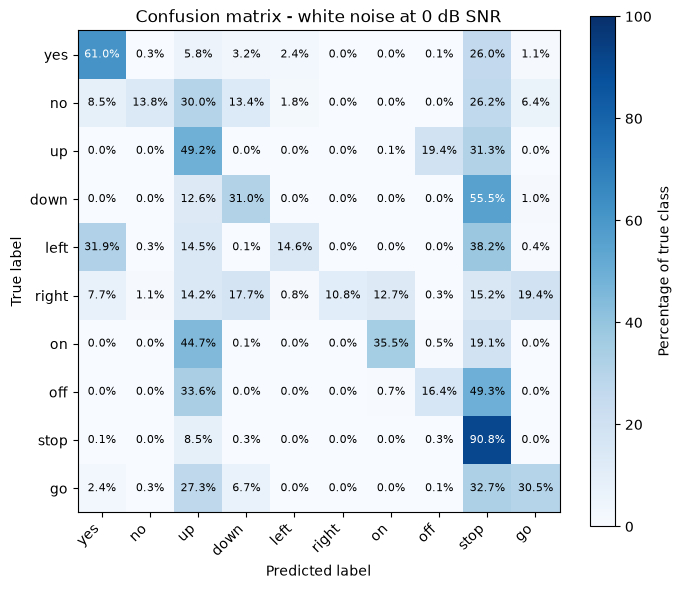

In [ ]:
# ---------------- VISUALIZE CLEAN/NOISY EXAMPLES AND CONFUSION MATRICES ----------------
EXAMPLE_WORD = "yes"
example_row = test_df[test_df["word"] == EXAMPLE_WORD].iloc[0]
clean_waveform, clean_sample_rate = load_and_fix_audio(example_row.filepath)
clean_feature = extract_log_mel_spectrogram(clean_waveform, clean_sample_rate)

for snr_db in [None] + SNR_LEVELS_DB:
    if snr_db is None:
        condition_name = "Clean"
        waveform = clean_waveform
        feature = clean_feature
    else:
        condition_name = f"White noise: {snr_db} dB SNR"
        rng = np.random.default_rng(NOISE_SEED + snr_db)
        waveform = add_white_noise(clean_waveform, snr_db, rng)
        feature = extract_log_mel_spectrogram(waveform, clean_sample_rate)

    time_axis = np.arange(len(waveform)) / clean_sample_rate
    fig, axes = plt.subplots(2, 2, figsize=(13, 7))

    axes[0, 0].plot(time_axis, clean_waveform, linewidth=0.7)
    axes[0, 0].set_title(f'Clean waveform: "{EXAMPLE_WORD}"')
    axes[0, 0].set_xlabel("Time (s)")
    axes[0, 0].set_ylabel("Amplitude")

    axes[0, 1].plot(time_axis, waveform, linewidth=0.7)
    axes[0, 1].set_title(f'{condition_name} waveform: "{EXAMPLE_WORD}"')
    axes[0, 1].set_xlabel("Time (s)")
    axes[0, 1].set_ylabel("Amplitude")

    clean_img = librosa.display.specshow(
        clean_feature,
        sr=clean_sample_rate,
        hop_length=FEATURE_PARAMS["hop_length"],
        x_axis="time",
        y_axis="mel",
        fmax=FEATURE_PARAMS["fmax"],
        ax=axes[1, 0],
    )
    axes[1, 0].set_title("Clean log-mel spectrogram")

    noisy_img = librosa.display.specshow(
        feature,
        sr=clean_sample_rate,
        hop_length=FEATURE_PARAMS["hop_length"],
        x_axis="time",
        y_axis="mel",
        fmax=FEATURE_PARAMS["fmax"],
        ax=axes[1, 1],
    )
    axes[1, 1].set_title(f"{condition_name} log-mel spectrogram")

    fig.colorbar(clean_img, ax=axes[1, 0], format="%+2.0f dB")
    fig.colorbar(noisy_img, ax=axes[1, 1], format="%+2.0f dB")
    fig.suptitle(f'Clean versus noisy example: "{EXAMPLE_WORD}" - {condition_name}', fontsize=14)
    plt.tight_layout()
    plt.show()

# Compute and display one normalized confusion matrix for every noise level.
confusion_matrices = {}
for snr_db in SNR_LEVELS_DB:
    X_test_noisy = build_noisy_test_features(snr_db, NOISE_SEED + snr_db)
    X_test_noisy = (X_test_noisy - mean) / std
    y_pred_noisy = np.argmax(
        model.predict(X_test_noisy, batch_size=BATCH_SIZE, verbose=0),
        axis=1,
    )

    cm = confusion_matrix(y_test, y_pred_noisy)
    confusion_matrices[snr_db] = cm
    cm_percent = cm / cm.sum(axis=1, keepdims=True) * 100

    fig, ax = plt.subplots(figsize=(7, 6))
    image = ax.imshow(cm_percent, cmap="Blues", vmin=0, vmax=100)
    ax.set_title(f"Confusion matrix - white noise at {snr_db} dB SNR")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.set_xticks(range(len(SELECTED_WORDS)))
    ax.set_xticklabels(SELECTED_WORDS, rotation=45, ha="right")
    ax.set_yticks(range(len(SELECTED_WORDS)))
    ax.set_yticklabels(SELECTED_WORDS)

    for row_index in range(cm.shape[0]):
        for column_index in range(cm.shape[1]):
            ax.text(
                column_index,
                row_index,
                f"{cm_percent[row_index, column_index]:.1f}%",
                ha="center",
                va="center",
                color="white" if cm_percent[row_index, column_index] > 50 else "black",
                fontsize=8,
            )

    fig.colorbar(image, ax=ax, label="Percentage of true class")
    plt.tight_layout()
    plt.show()

## 4.2 Real-world background noise

In [19]:
BACKGROUND_NOISE_DIR = RAW_DIR / "_background_noise_"
REAL_BACKGROUND_NAMES = {
    "doing_the_dishes.wav",
    "dude_miaowing.wav",
    "exercise_bike.wav",
    "running_tap.wav",
}

background_paths = sorted(
    path for path in BACKGROUND_NOISE_DIR.glob("*.wav")
    if path.name in REAL_BACKGROUND_NAMES
)

assert background_paths, f"No background-noise recordings found in {BACKGROUND_NOISE_DIR}"

background_library = []
for background_path in background_paths:
    background_waveform, _ = librosa.load(
        background_path, sr=TARGET_SR, mono=True
    )
    background_library.append(background_waveform.astype(np.float32))

print("Background recordings:")
for background_path in background_paths:
    print(f"  {background_path.name}")


def get_background_segment(length, rng):
    """Return a random background segment with exactly `length` samples."""
    background = background_library[rng.integers(len(background_library))]

    if len(background) < length:
        repeats = int(np.ceil(length / len(background)))
        background = np.tile(background, repeats)

    max_start = len(background) - length
    start = rng.integers(max_start + 1) if max_start > 0 else 0
    return background[start:start + length].copy()


def add_background_noise(y, snr_db, rng):
    """Mix a real background recording into y at the requested SNR."""
    signal_rms = np.sqrt(np.mean(y ** 2))
    background = get_background_segment(len(y), rng)
    background_rms = np.sqrt(np.mean(background ** 2))

    if signal_rms == 0 or background_rms == 0:
        return y.copy()

    target_background_rms = signal_rms / (10 ** (snr_db / 20))
    background = background * (target_background_rms / background_rms)
    return (y + background).astype(np.float32)


def build_background_noisy_test_features(snr_db, seed):
    """Add real background noise to test audio and extract log-mel features."""
    rng = np.random.default_rng(seed)
    features = []

    for filepath in test_df["filepath"]:
        waveform, sample_rate = load_and_fix_audio(filepath)
        noisy_waveform = add_background_noise(waveform, snr_db, rng)
        feature = extract_log_mel_spectrogram(noisy_waveform, sample_rate)
        features.append(feature)

    return np.stack(features, axis=0)[..., np.newaxis]


background_noise_results = []
for snr_db in SNR_LEVELS_DB:
    print(f"Evaluating real background noise at {snr_db} dB SNR...")

    X_test_background = build_background_noisy_test_features(
        snr_db, NOISE_SEED + 1000 + snr_db
    )
    X_test_background = (X_test_background - mean) / std

    noisy_loss, noisy_accuracy = model.evaluate(
        X_test_background, y_test, batch_size=BATCH_SIZE, verbose=0
    )
    background_noise_results.append({
        "SNR_dB": snr_db,
        "test_loss": noisy_loss,
        "test_accuracy": noisy_accuracy,
    })

background_noise_results = pd.DataFrame(background_noise_results).sort_values(
    "SNR_dB", ascending=False
)
print("\nPerformance under real-world background noise:")
display(background_noise_results)


Background recordings:
  doing_the_dishes.wav
  dude_miaowing.wav
  exercise_bike.wav
  running_tap.wav
Evaluating real background noise at 30 dB SNR...
Evaluating real background noise at 20 dB SNR...
Evaluating real background noise at 10 dB SNR...
Evaluating real background noise at 0 dB SNR...

Performance under real-world background noise:


,SNR_dB,test_loss,test_accuracy
0,30,0.280706,0.905755
1,20,0.413805,0.854879
2,10,0.754907,0.728246
3,0,1.630830,0.390047


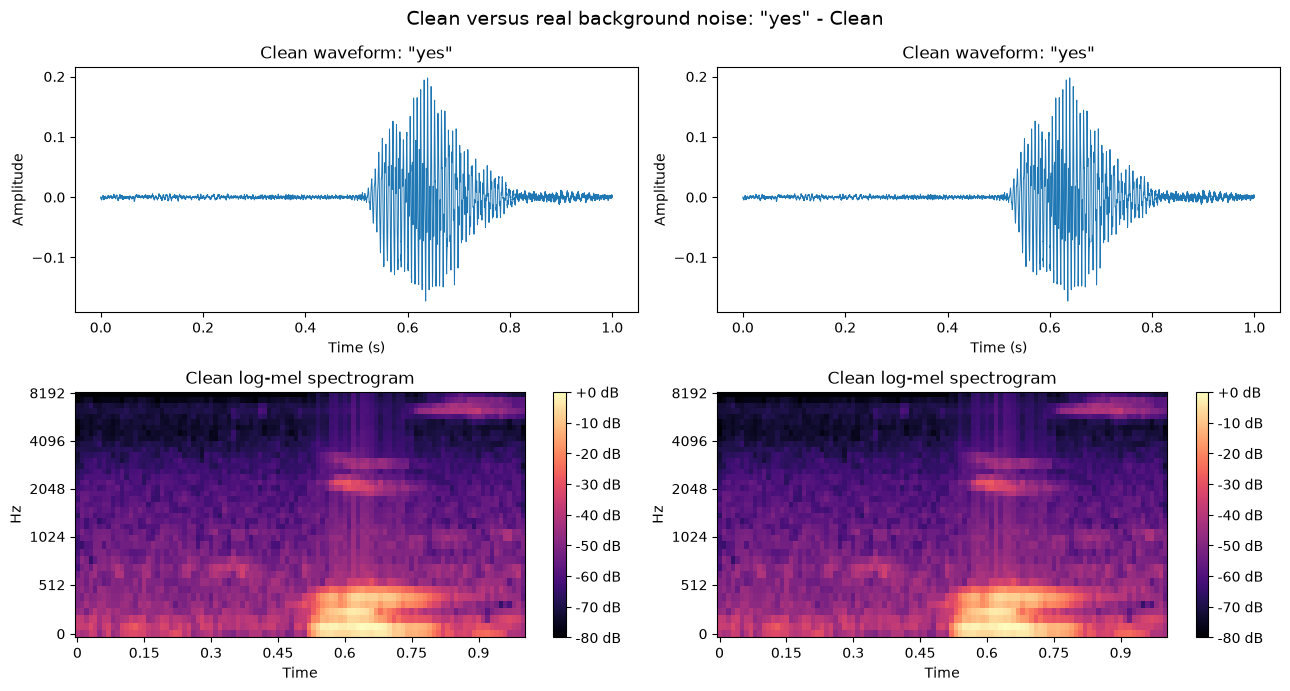

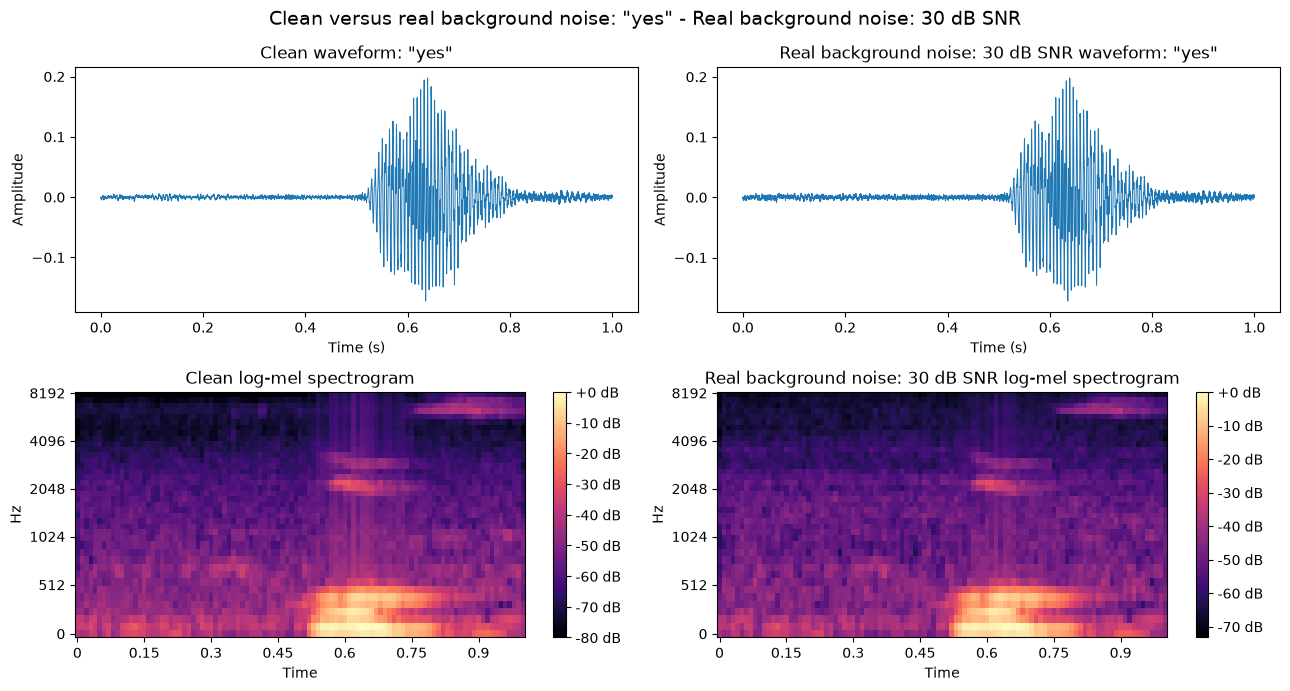

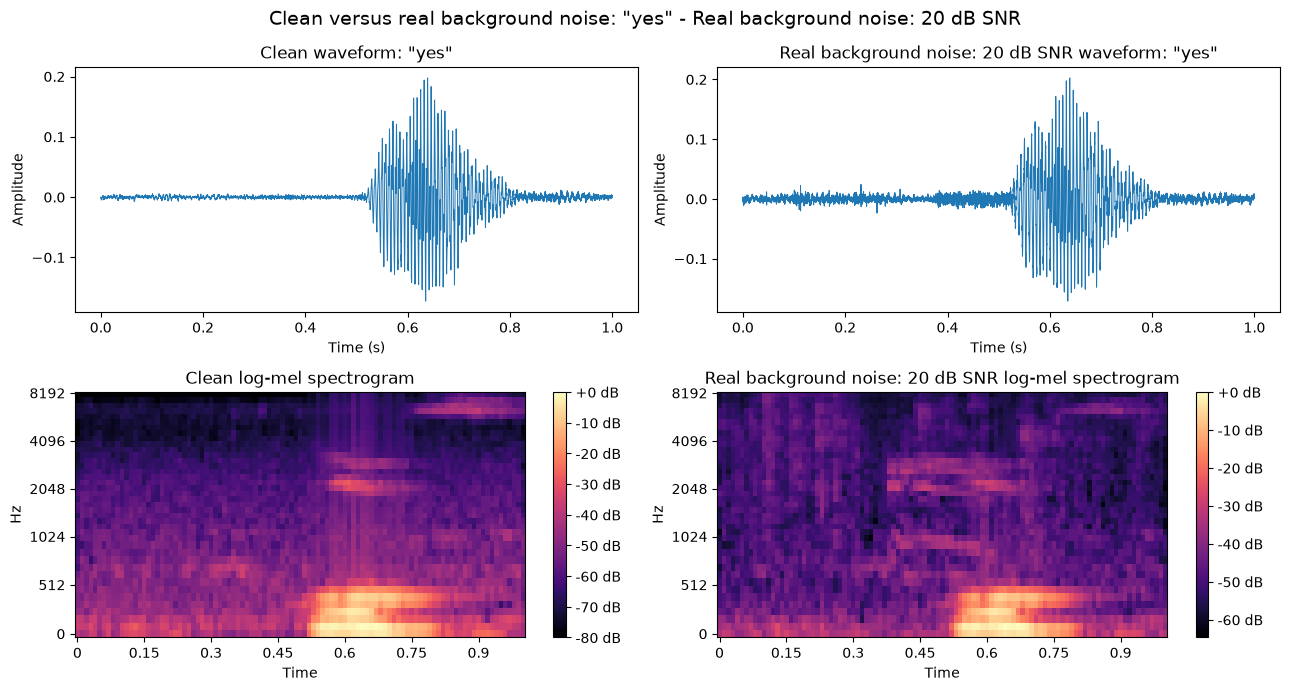

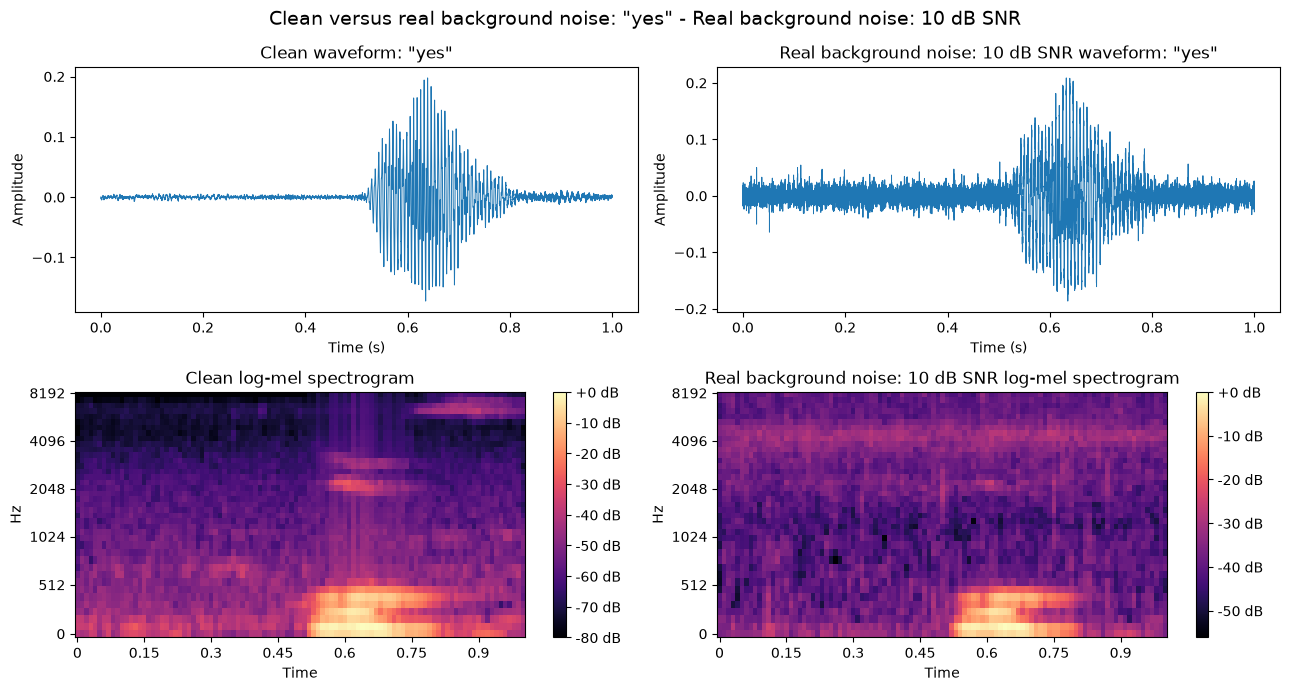

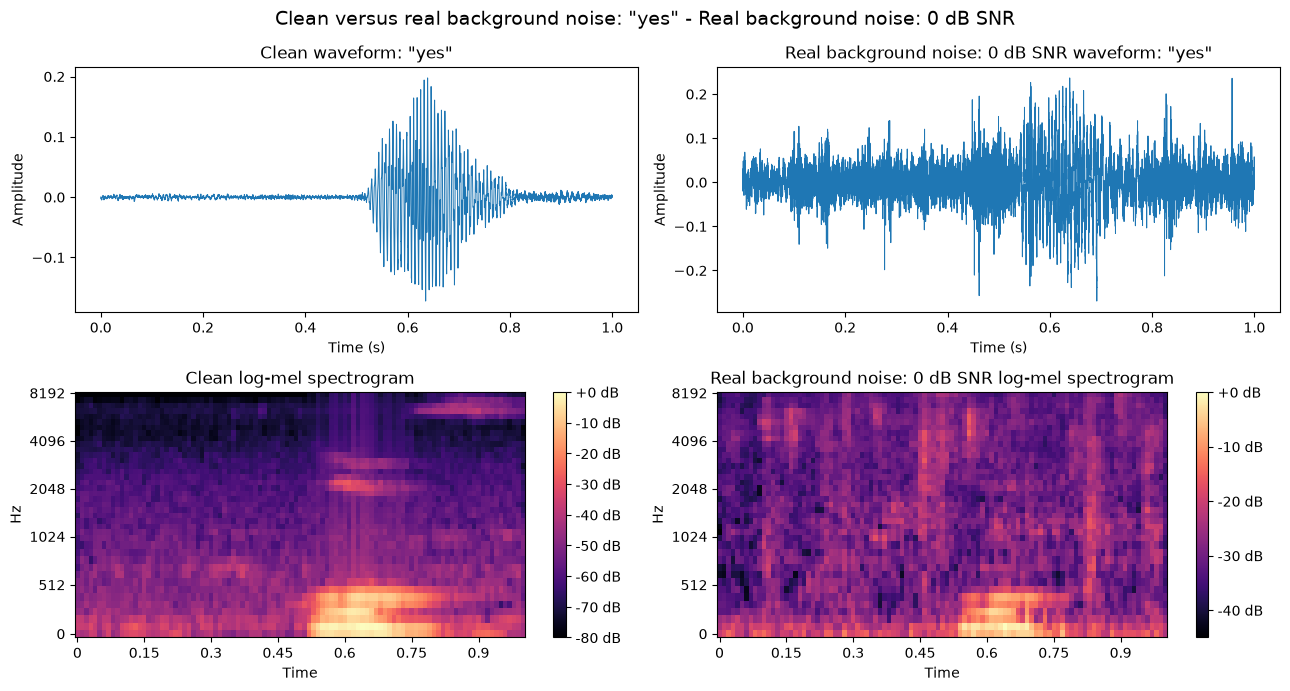

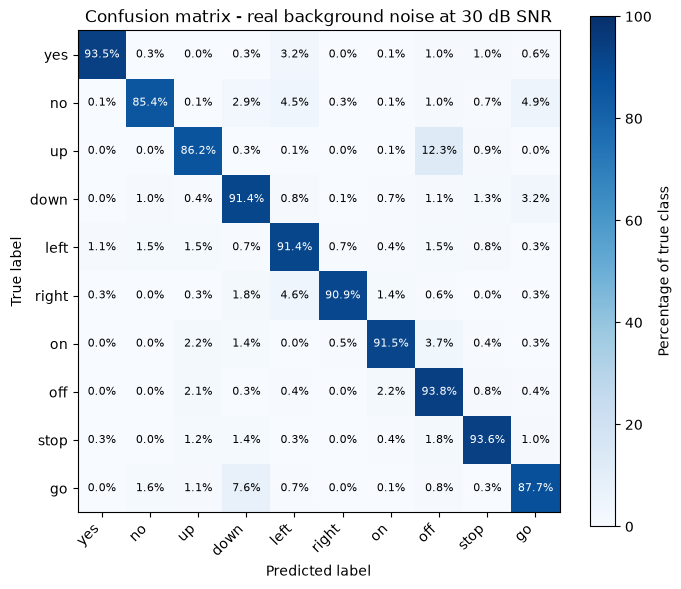

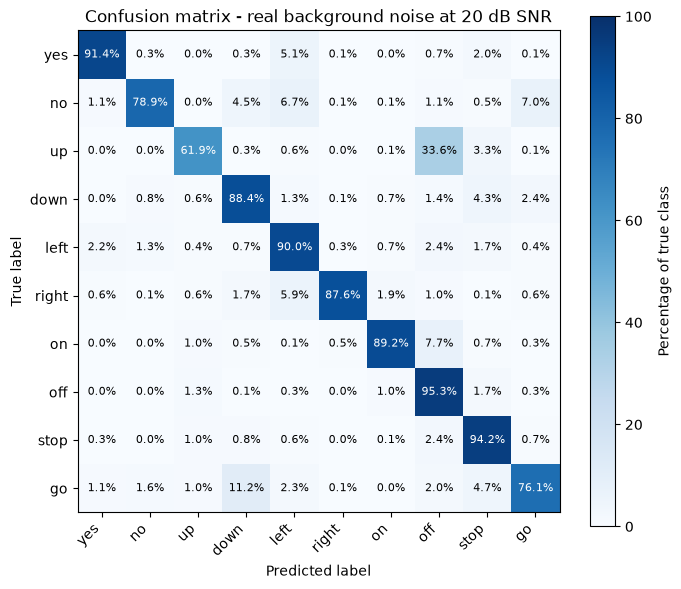

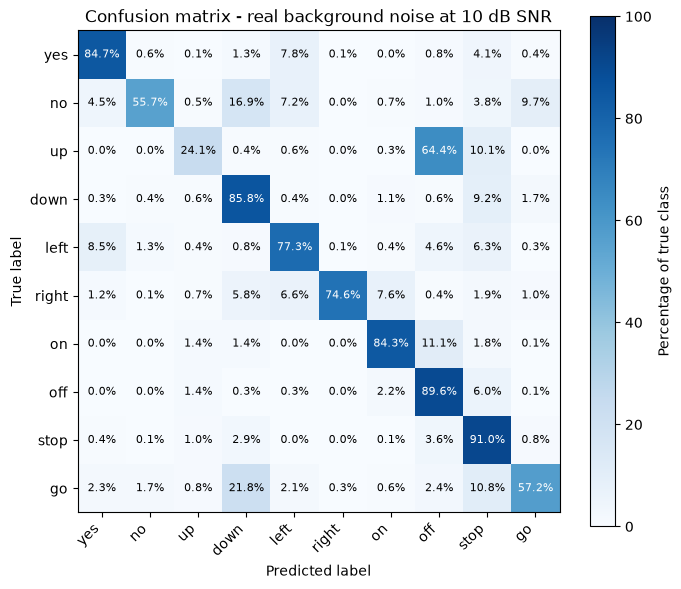

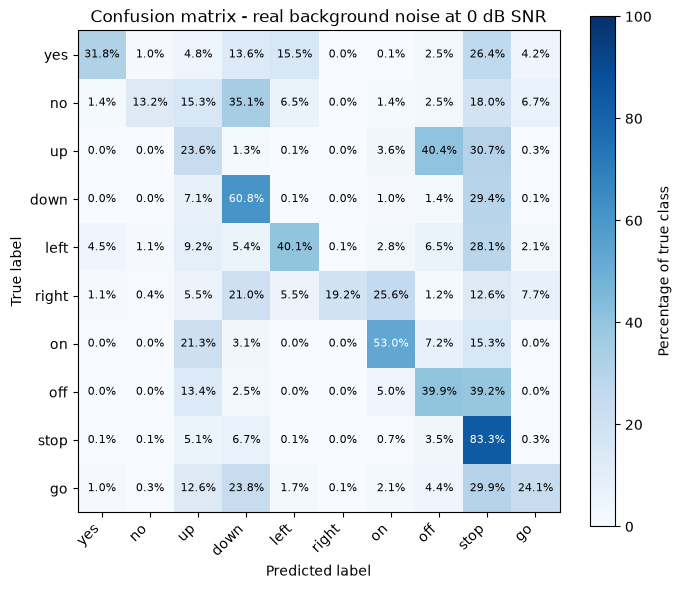

In [20]:
# ---------------- VISUALIZE REAL BACKGROUND NOISE AND CONFUSION MATRICES ----------------
EXAMPLE_WORD = "yes"
example_row = test_df[test_df["word"] == EXAMPLE_WORD].iloc[0]
clean_waveform, clean_sample_rate = load_and_fix_audio(example_row.filepath)
clean_feature = extract_log_mel_spectrogram(clean_waveform, clean_sample_rate)

# Plot the same utterance under clean conditions and real background noise.
for snr_db in [None] + SNR_LEVELS_DB:
    if snr_db is None:
        condition_name = "Clean"
        waveform = clean_waveform
        feature = clean_feature
    else:
        condition_name = f"Real background noise: {snr_db} dB SNR"
        rng = np.random.default_rng(NOISE_SEED + 1000 + snr_db)
        waveform = add_background_noise(clean_waveform, snr_db, rng)
        feature = extract_log_mel_spectrogram(waveform, clean_sample_rate)

    time_axis = np.arange(len(waveform)) / clean_sample_rate
    fig, axes = plt.subplots(2, 2, figsize=(13, 7))

    axes[0, 0].plot(time_axis, clean_waveform, linewidth=0.7)
    axes[0, 0].set_title(f'Clean waveform: "{EXAMPLE_WORD}"')
    axes[0, 0].set_xlabel("Time (s)")
    axes[0, 0].set_ylabel("Amplitude")

    axes[0, 1].plot(time_axis, waveform, linewidth=0.7)
    axes[0, 1].set_title(f'{condition_name} waveform: "{EXAMPLE_WORD}"')
    axes[0, 1].set_xlabel("Time (s)")
    axes[0, 1].set_ylabel("Amplitude")

    clean_img = librosa.display.specshow(
        clean_feature,
        sr=clean_sample_rate,
        hop_length=FEATURE_PARAMS["hop_length"],
        x_axis="time",
        y_axis="mel",
        fmax=FEATURE_PARAMS["fmax"],
        ax=axes[1, 0],
    )
    axes[1, 0].set_title("Clean log-mel spectrogram")

    noisy_img = librosa.display.specshow(
        feature,
        sr=clean_sample_rate,
        hop_length=FEATURE_PARAMS["hop_length"],
        x_axis="time",
        y_axis="mel",
        fmax=FEATURE_PARAMS["fmax"],
        ax=axes[1, 1],
    )
    axes[1, 1].set_title(f"{condition_name} log-mel spectrogram")

    fig.colorbar(clean_img, ax=axes[1, 0], format="%+2.0f dB")
    fig.colorbar(noisy_img, ax=axes[1, 1], format="%+2.0f dB")
    fig.suptitle(f'Clean versus real background noise: "{EXAMPLE_WORD}" - {condition_name}', fontsize=14)
    plt.tight_layout()
    plt.show()

# Compute and display one normalized confusion matrix for every real-noise level.
background_confusion_matrices = {}
for snr_db in SNR_LEVELS_DB:
    X_test_background = build_background_noisy_test_features(
        snr_db, NOISE_SEED + 1000 + snr_db
    )
    X_test_background = (X_test_background - mean) / std
    y_pred_background = np.argmax(
        model.predict(X_test_background, batch_size=BATCH_SIZE, verbose=0),
        axis=1,
    )

    cm = confusion_matrix(y_test, y_pred_background)
    background_confusion_matrices[snr_db] = cm
    cm_percent = cm / cm.sum(axis=1, keepdims=True) * 100

    fig, ax = plt.subplots(figsize=(7, 6))
    image = ax.imshow(cm_percent, cmap="Blues", vmin=0, vmax=100)
    ax.set_title(f"Confusion matrix - real background noise at {snr_db} dB SNR")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.set_xticks(range(len(SELECTED_WORDS)))
    ax.set_xticklabels(SELECTED_WORDS, rotation=45, ha="right")
    ax.set_yticks(range(len(SELECTED_WORDS)))
    ax.set_yticklabels(SELECTED_WORDS)

    for row_index in range(cm.shape[0]):
        for column_index in range(cm.shape[1]):
            ax.text(
                column_index,
                row_index,
                f"{cm_percent[row_index, column_index]:.1f}%",
                ha="center",
                va="center",
                color="white" if cm_percent[row_index, column_index] > 50 else "black",
                fontsize=8,
            )

    fig.colorbar(image, ax=ax, label="Percentage of true class")
    plt.tight_layout()
    plt.show()